### EMERGENT Analysis: Notebook 3
#### Training a model to predict PANSS scores

### 1 - Setup

Load necessary packages, define relevant paths for data and storing figures.

In [1]:
%load_ext rpy2.ipython

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns
from tqdm import tqdm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from matplotlib.patches import Patch
from sklearn.metrics import mean_squared_error, r2_score 
from scipy.stats import pearsonr

from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

import sys
sys.path.append('/home/ssm-user/bklynhlth-science/common_functions/')
from analysis import (
    scatterplot, boxplot_ttest, distribution,
    calculate_labelpad_and_left, mlr_test, cohens_d, lme_test,
    train_and_test, plot_feature_importance, scatterplot_rmse,
    train_rf_model, test_rf_model, boxplot_sites_multiple,
    boxplot_anova, distribution_grid, boxplot_sites, boxplot_sites_adj, 
    tukey_anova, boxplot_visits, boxplot_visits_multiple, boxplot_sites
)
from study_data import remove_outliers

pd.set_option('display.max_rows', None)
warnings.simplefilter(action='ignore', category=FutureWarning)

from rpy2.robjects import pandas2ri
import rpy2.robjects as ro
from rpy2.robjects.conversion import localconverter

# Activate pandas2ri to convert pandas dataframe into R dataframes
pandas2ri.activate()

In [3]:
%%R
library(lmerTest)
library(effectsize) # for partial eta2 values
library(performance) # for Nakagawa conditional/marginal R2

lme_test <- function(df_temp, dep_var, ind_vars, random_effects, print_stats=FALSE, fit_reduced=FALSE) {
  # Construct the formula for the full model
  fixed_effects <- paste(c(ind_vars, random_effects[2]), collapse = " + ")
  formula_full <- as.formula(paste(dep_var, "~", fixed_effects, "+ (", random_effects[2],"|", random_effects[1], ")"))
    
  # Fit the full model
  model_full <- lmerTest::lmer(formula_full, data = df_temp)
  
  # Get results for the variable of interest
  summary_full <- summary(model_full)
  pval <- summary_full$coefficients[ind_vars[1], "Pr(>|t|)"]
  coef <- summary_full$coefficients[ind_vars[1], "Estimate"]
  conf_int <- confint(model_full, parm = ind_vars[1], level = 0.95)
  
  if (print_stats) {
    print(summary_full)
  }
  
  if (!fit_reduced) {
    return(list(pval = pval, coef = coef, partial_r2 = NULL, part_r2 = NULL, conf_int = conf_int))
  }

  # Construct the formula for the reduced model (excluding the first independent variable)
  fixed_effects_reduced <- paste(c(ind_vars[-1], random_effects[2]), collapse = " + ")
  formula_reduced <- as.formula(paste(dep_var, "~", fixed_effects_reduced, "+ (", random_effects[2],"|", random_effects[1], ")"))
  
  # Fit the reduced model
  model_reduced <- lmer(formula_reduced, data = df_temp)
  
  # Calculate marginal R-squared for full and reduced models
  r2_full <- r2_nakagawa(model_full)
  r2_reduced <- r2_nakagawa(model_reduced)
  full_marginal_r2 <- r2_full$R2_marginal
  reduced_marginal_r2 <- r2_reduced$R2_marginal
  
  # Partial R2 calculation
  partial_r2 <- (full_marginal_r2 - reduced_marginal_r2) / (1 - reduced_marginal_r2)
   
  # Partial eta2 calculation
  eta_sq_results <- eta_squared(model_full, partial = TRUE)

  return(list(pval = pval, coef = coef, partial_r2 = as.numeric(partial_r2), part_r2 = NULL, partial_eta2 = as.numeric(eta_sq_results$Eta2_partial[1]), conf_int = conf_int))
}

step_forward_selection <- function(df_temp, dep_var, initial_vars, ind_vars, random_effects) {
  selected_vars <- initial_vars
  remaining_vars <- ind_vars
  best_model <- NULL
  best_pval <- 1
  alpha <- 0.05
  n_tests <- length(ind_vars)
    
  vars <- c()
  stats <- c()
  
  while (length(remaining_vars) > 0) {
    pval_values <- sapply(remaining_vars, function(var) {
      current_vars <- c(selected_vars, var)
      fixed_effects <- paste(c(current_vars, random_effects[2]), collapse = " + ")
      formula_current <- as.formula(paste(dep_var, "~", fixed_effects, "+ (", random_effects[2], "|", random_effects[1], ")"))
      model_current <- lmer(formula_current, data = df_temp)
      summary_current <- summary(model_current)
      return(summary_current$coefficients[var, "Pr(>|t|)"])
    })
    
    best_var <- remaining_vars[which.min(pval_values)]
    best_var_pval <- min(pval_values)
    
    if (best_var_pval < (alpha / n_tests)) {
      res <- lme_test(df_temp, dep_var, c(best_var, selected_vars), random_effects, fit_reduced=TRUE)
      stats <- rbind(stats, c(res$partial_r2, res$partial_eta2))
      vars <- c(vars, best_var)
        
      best_pval <- best_var_pval
      selected_vars <- c(selected_vars, best_var)
      remaining_vars <- setdiff(remaining_vars, best_var)
      fixed_effects <- paste(c(selected_vars, random_effects[2]), collapse = " + ")
      formula_best <- as.formula(paste(dep_var, "~", fixed_effects, "+ (", random_effects[2], "|", random_effects[1], ")"))
      best_model <- lmer(formula_best, data = df_temp)
      n_tests <- length(remaining_vars)
      
    } else {
      break
    }
  }
  
  return(list(best_model = best_model, vars = vars, stats = stats))
}

Loading required package: lme4
Loading required package: Matrix

Attaching package: ‘lmerTest’

The following object is masked from ‘package:lme4’:

    lmer

The following object is masked from ‘package:stats’:

    step



In [4]:
figure_dir = '/home/ssm-user/bklynhlth-science/michelleworthington/emergent_analysis/figures/final_figures/notebook3_models/'

#### 1.1 - Load data

Load compiled data from first notebook.

In [5]:
df = pd.read_csv('/home/ssm-user/bklynhlth-science/datasets/datasets_engagements/emergent/emergent_analysis_df.csv')

In [8]:
# define DHMs
dhms = ['file_length', 'speech_length_in_minutes_adjusted',
       'speech_length_in_words_adjusted',
       'mean_turn_length_in_minutes', 'mean_turn_length_in_words',
       'speaker_percentage',
       'words_per_minute', 'syllables_per_minute',
       'word_pause_length_mean', 'word_pause_variability',
       'mean_pre_turn_pause', 'positive_sentiment', 'negative_sentiment',
       'lexical_richness',
       'first_person_percentage',
       'first_person_sentiment_positive', 'first_person_sentiment_negative',
       'first_person_sentiment_overall', 'word_repeat_percentage',
       'phrase_repeat_percentage',
       'word_coherence_mean', 'word_coherence_var', 'word_coherence_5_mean',
       'word_coherence_5_var', 'word_coherence_10_mean',
       'word_coherence_10_var', 'word_coherence_variability_2_mean',
       'word_coherence_variability_2_var', 'word_coherence_variability_3_mean',
       'word_coherence_variability_3_var', 'word_coherence_variability_4_mean',
       'word_coherence_variability_4_var', 'word_coherence_variability_5_mean',
       'word_coherence_variability_5_var', 'word_coherence_variability_6_mean',
       'word_coherence_variability_6_var', 'word_coherence_variability_7_mean',
       'word_coherence_variability_7_var', 'word_coherence_variability_8_mean',
       'word_coherence_variability_8_var', 'word_coherence_variability_9_mean',
       'word_coherence_variability_9_var',
       'word_coherence_variability_10_mean',
       'word_coherence_variability_10_var',
       'first_order_sentence_tangeniality_mean',
       'first_order_sentence_tangeniality_var',
       'second_order_sentence_tangeniality_mean',
       'second_order_sentence_tangeniality_var',
       'turn_to_turn_tangeniality_mean', 'turn_to_turn_tangeniality_var',
       'turn_to_turn_tangeniality_slope', 'semantic_perplexity_mean',
       'semantic_perplexity_var', 'f0_mean', 'f0_stddev', 'f1_mean', 'f1_stddev', 
       'f2_mean', 'f2_stddev', 'f3_mean', 'f3_stddev', 'f4_mean', 'f4_stddev',
       'loudness_mean', 'loudness_stddev', 'hnr_mean',
       'hnr_stddev', 'jitter', 'jitter_abs',
       'jitter_rap', 'jitter_ppq5', 'jitter_ddp', 'shimmer', 'shimmer_db',
       'shimmer_apq3', 'shimmer_apq5', 'shimmer_apq11', 'shimmer_dda',
       'gne_ratio', 'silence_ratio']

In [10]:
# creating a dataframe that has data from screening only

df_screening = df[df['visit'] == 1].drop_duplicates(subset='id', keep='first')

In [11]:
df_clean = remove_outliers(df.copy(), dhms)
df_screening_clean = remove_outliers(df_screening.copy(), dhms)

### 2 - Model development

This section goes through steps to train random forest models to predict PANSS scores across the three EMERGENT trials. Throughout, models are iteratively trained on data from 2/3 of the trials and tested on data from the heldout trial. Model performance is assessed based on root mean squared error (RMSE), a measure of the distance in predicted scores from actual scores. Outcomes of interest include PANSS total score in addition to the PANSS-P and PANSS-N subscales.

In [12]:
features = ['age', 'male', 'black'] + dhms[1:]

In [13]:
df_train_a = df_clean[df_clean['study'].isin(['kar004', 'kar007'])].reset_index()
df_test_a = df_clean[df_clean['study']=='kar009'].reset_index()

In [14]:
df_train_b = df_clean[df_clean['study'].isin(['kar004', 'kar009'])].reset_index()
df_test_b = df_clean[df_clean['study']=='kar007'].reset_index()

In [15]:
df_train_c = df_clean[df_clean['study'].isin(['kar007', 'kar009'])].reset_index()
df_test_c = df_clean[df_clean['study']=='kar004'].reset_index()

In [16]:
pt_ids = df.id.unique()

np.random.seed(123)
np.random.shuffle(pt_ids)

split_index = int(len(pt_ids) * 0.8)
train_pt_ids = pt_ids[:split_index]
test_pt_ids = pt_ids[split_index:]

df_train_d = df_clean[df_clean.id.isin(train_pt_ids)]
df_test_d = df_clean[df_clean.id.isin(test_pt_ids)]

#### 2.1 - Predicting PANSS scores

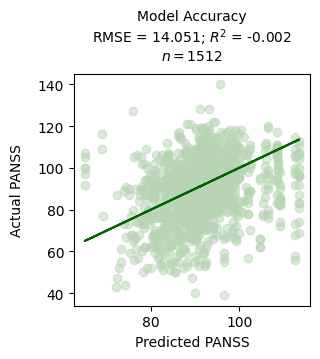

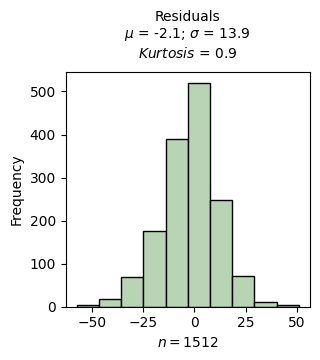

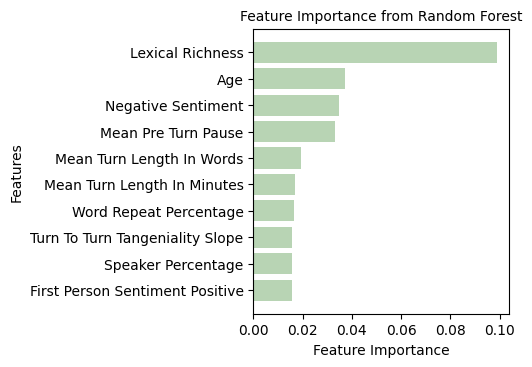

In [17]:
# Model A
# training, testing a model and getting residuals from testing
residuals_overall_a, estimates_overall_a, model_overall_a = train_and_test('panss', features, df_train_a, df_test_a, dpi=100)
residuals_overall_a, estimates_overall_a, model_overall_a = train_and_test('panss', features, df_train_a, df_test_a, dpi=200, filename=figure_dir+f"2.1_scatterplot_model-A_panss_rmse.png")

# plotting distributions of the residuals
distribution(residuals_overall_a, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_overall_a, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.1_histogram_model-A_panss_residuals.png")

# feature importance
plot_feature_importance(model_overall_a, features, dpi=100)
plot_feature_importance(model_overall_a, features, dpi=200, filename=figure_dir+f"2.1_feature-imp_model-A_panss.png")

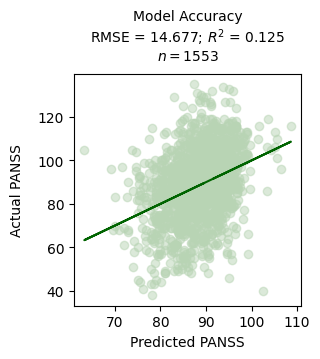

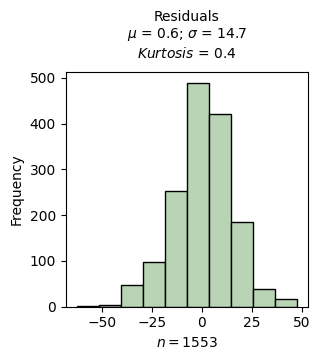

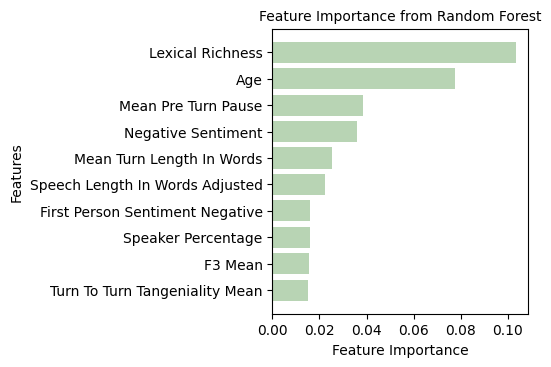

In [18]:
# Model B
# training, testing a model and getting residuals from testing
residuals_overall_b, estimates_overall_b, model_overall_b = train_and_test('panss', features, df_train_b, df_test_b, dpi=100)
residuals_overall_b, estimates_overall_b, model_overall_b = train_and_test('panss', features, df_train_b, df_test_b, dpi=200, filename=figure_dir+f"2.1_scatterplot_model-B_panss_rmse.png")

# plotting distributions of the residuals
distribution(residuals_overall_b, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_overall_b, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.1_histogram_model-B_panss_residuals.png")

# feature importance
plot_feature_importance(model_overall_b, features, dpi=100)
plot_feature_importance(model_overall_b, features, dpi=200, filename=figure_dir+f"2.1_feature-imp_model-B_panss.png")

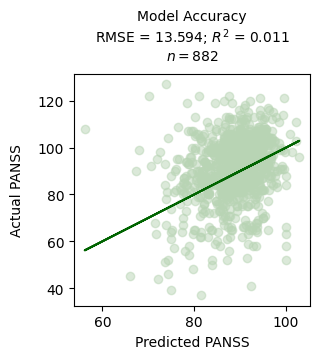

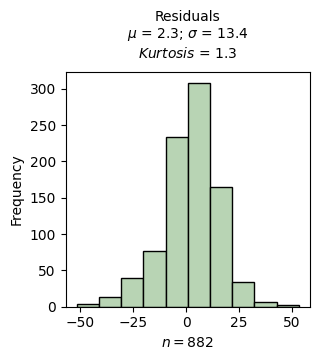

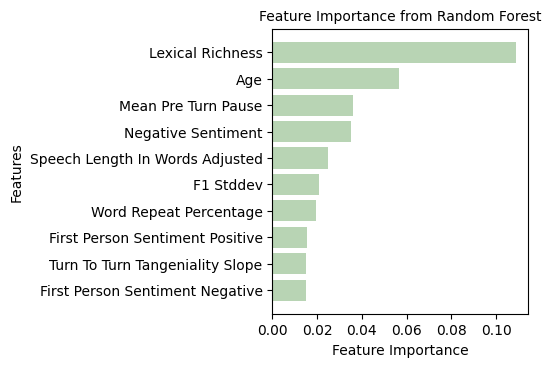

In [19]:
# Model C
# training, testing a model and getting residuals from testing
residuals_overall_c, estimates_overall_c, model_overall_c = train_and_test('panss', features, df_train_c, df_test_c, dpi=100)
residuals_overall_c, estimates_overall_c, model_overall_c = train_and_test('panss', features, df_train_c, df_test_c, dpi=200, filename=figure_dir+f"2.1_scatterplot_model-C_panss_rmse.png")

# plotting distributions of the residuals
distribution(residuals_overall_c, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_overall_c, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.1_histogram_model-C_panss_residuals.png")

# feature importance
plot_feature_importance(model_overall_c, features, dpi=100)
plot_feature_importance(model_overall_c, features, dpi=200, filename=figure_dir+f"2.1_feature-imp_model-C_panss.png")

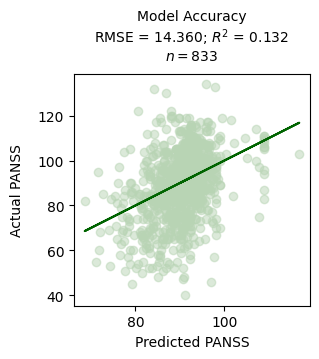

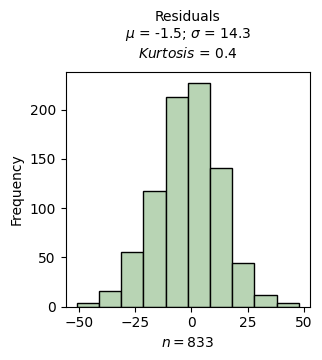

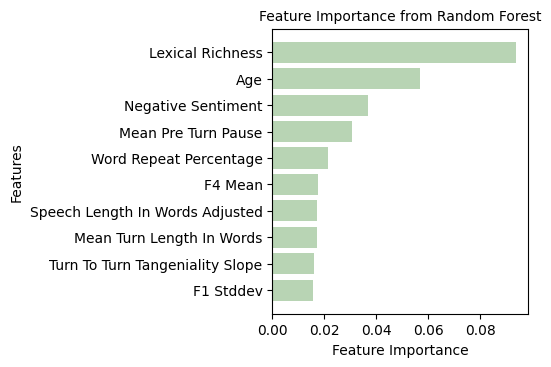

In [20]:
# Model D
# training, testing a model and getting residuals from testing
residuals_overall_d, estimates_overall_d, model_overall_d = train_and_test('panss', features, df_train_d, df_test_d, dpi=100)
residuals_overall_d, estimates_overall_d, model_overall_d = train_and_test('panss', features, df_train_d, df_test_d, dpi=200, filename=figure_dir+f"2.1_scatterplot_model-D_panss_rmse.png")

# plotting distributions of the residuals
distribution(residuals_overall_d, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_overall_d, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.1_histogram_model-D_panss_residuals.png")

# feature importance
plot_feature_importance(model_overall_d, features, dpi=100)
plot_feature_importance(model_overall_d, features, dpi=200, filename=figure_dir+f"2.1_feature-imp_model-D_panss.png")

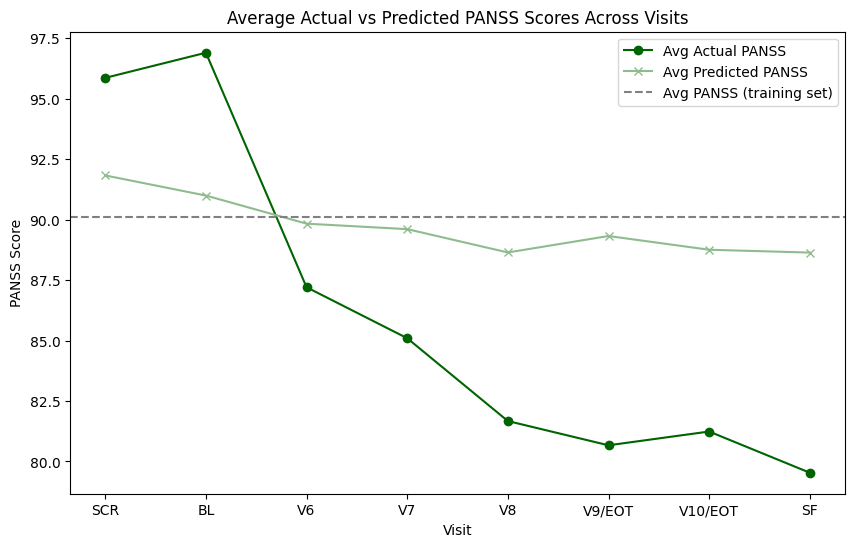

In [21]:
# Average PANSS score in training dataset
avg_panss_train = np.mean(df_train_d['panss'])

# Create a temporary DataFrame to combine Visit and predicted scores
temp_df = pd.DataFrame({'visit_name': df_test_d['visit_name'], 'predicted_panss': estimates_overall_d.iloc[:,0], 'actual_panss': df_test_d['panss']})

# Calculate average actual and predicted PANSS scores for each visit
avg_scores = temp_df.groupby('visit_name')[['actual_panss', 'predicted_panss']].mean().reset_index()

# ensure visits show up in order
visit_order = ['SCR', 'BL', 'V6', 'V7', 'V8', 'V9/EOT', 'V10/EOT', 'SF'] 
avg_scores['visit_name'] = pd.Categorical(avg_scores['visit_name'], categories = visit_order, ordered = True)
avg_scores = avg_scores.sort_values('visit_name')

# Plotting
plt.figure(figsize=(10, 6))  # Adjust figure size as needed

# Plot average actual and predicted PANSS scores
plt.plot(avg_scores['visit_name'], avg_scores['actual_panss'], label = 'Avg Actual PANSS', marker = 'o', color = 'darkgreen')
plt.plot(avg_scores['visit_name'], avg_scores['predicted_panss'], label = 'Avg Predicted PANSS', marker = 'x', color = 'darkseagreen')

# Horizontal line for average predicted PANSS from training set
plt.axhline(y = avg_panss_train, color = 'gray', linestyle = '--', label = 'Avg PANSS (training set)')

# Calculate and display Pearson correlation at each visit (using original data)
for visit in df_test_d['visit_name'].unique():
    visit_data = df_test_d[df_test_d['visit_name'] == visit]
    visit_predictions = temp_df[temp_df['visit_name'] == visit]['predicted_panss']
    
    #corr, p_value = pearsonr(visit_data['panss'], visit_predictions)
    #avg_predicted_for_visit = avg_scores[avg_scores['visit_name'] == visit]['predicted_panss'].values[0]
    #plt.text(visit, max(visit_data['panss'].mean(), avg_predicted_for_visit) + 0.5, f'r={corr:.2f}', ha='center')

# Add labels, legend, and title
plt.xlabel('Visit')
plt.ylabel('PANSS Score')
#plt.ylim(76,99)
plt.title('Average Actual vs Predicted PANSS Scores Across Visits')
plt.legend()
plt.grid(False)
plt.show()

#### 2.2 - Predicting positive symptoms (PANSS-P)

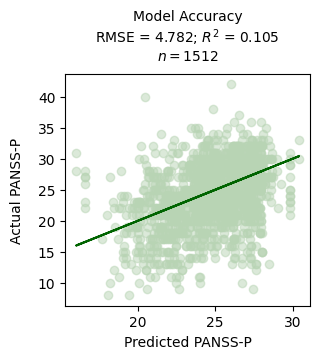

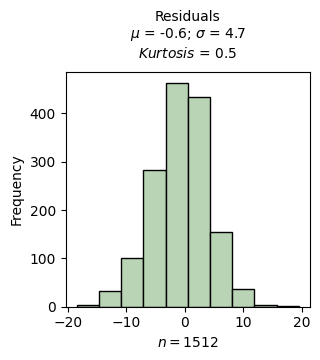

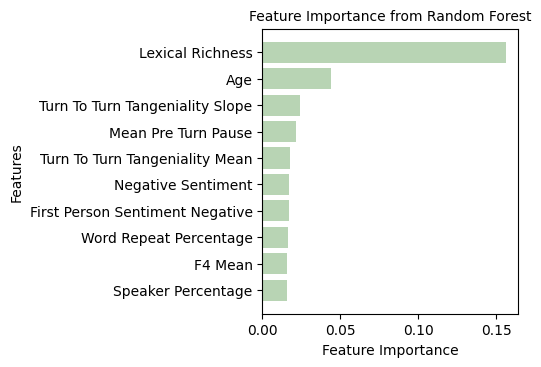

In [22]:
# Model A
# training, testing a model and getting residuals from testing
residuals_positive_a, estimates_positive_a, model_positive_a = train_and_test('panss_ptot', features, df_train_a, df_test_a, dpi=100)
residuals_positive_a, estimates_positive_a, model_positive_a = train_and_test('panss_ptot', features, df_train_a, df_test_a, dpi=200, filename=figure_dir+f"2.2_scatterplot_model-A_panss-positive_rmse.png")

# plotting distributions of the residuals
distribution(residuals_positive_a, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_positive_a, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.2_histogram_model-A_panss-positive_residuals.png")

# feature importance
plot_feature_importance(model_positive_a, features, dpi=100)
plot_feature_importance(model_positive_a, features, dpi=200, filename=figure_dir+f"2.2_feature-imp_model-A_panss-positive.png")

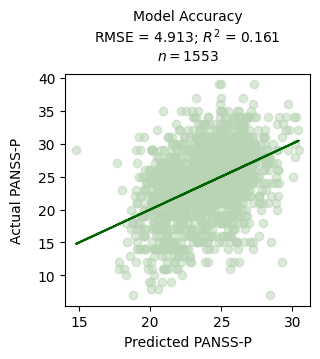

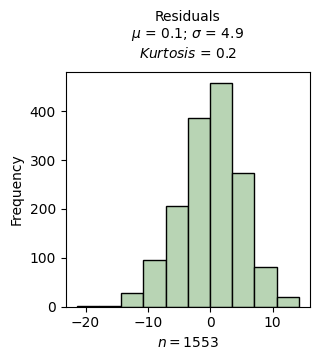

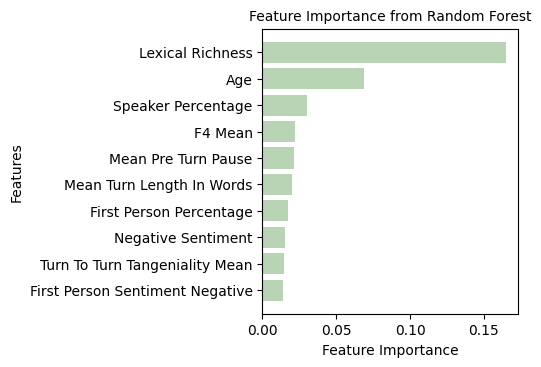

In [23]:
# Model B
# training, testing a model and getting residuals from testing
residuals_positive_b, estimates_positive_b, model_positive_b = train_and_test('panss_ptot', features, df_train_b, df_test_b, dpi=100)
residuals_positive_b, estimates_positive_b, model_positive_b = train_and_test('panss_ptot', features, df_train_b, df_test_b, dpi=200, filename=figure_dir+f"2.2_scatterplot_model-B_panss-positive_rmse.png")

# plotting distributions of the residuals
distribution(residuals_positive_b, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_positive_b, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.2_histogram_model-B_panss-positive_residuals.png")

# feature importance
plot_feature_importance(model_positive_b, features, dpi=100)
plot_feature_importance(model_positive_b, features, dpi=200, filename=figure_dir+f"2.2_feature-imp_model-B_panss-positive.png")

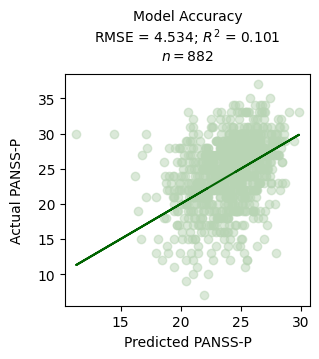

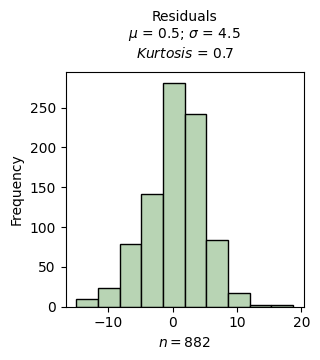

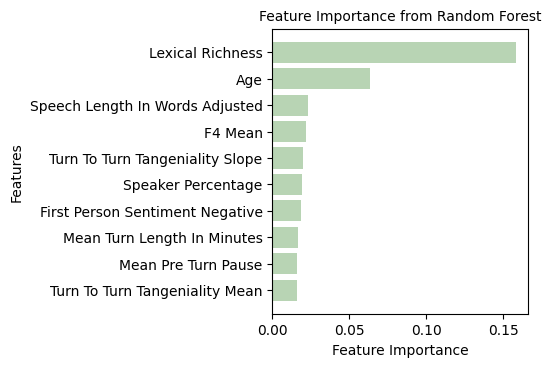

In [24]:
# Model C
# training, testing a model and getting residuals from testing
residuals_positive_c, estimates_positive_c, model_positive_c = train_and_test('panss_ptot', features, df_train_c, df_test_c, dpi=100)
residuals_positive_c, estimates_positive_c, model_positive_c = train_and_test('panss_ptot', features, df_train_c, df_test_c, dpi=200, filename=figure_dir+f"2.2_scatterplot_model-C_panss-positive_rmse.png")

# plotting distributions of the residuals
distribution(residuals_positive_c, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_positive_c, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.2_histogram_model-C_panss-positive_residuals.png")

# feature importance
plot_feature_importance(model_positive_c, features, dpi=100)
plot_feature_importance(model_positive_c, features, dpi=200, filename=figure_dir+f"2.2_feature-imp_model-C_panss-positive.png")

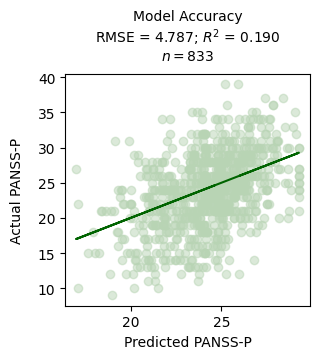

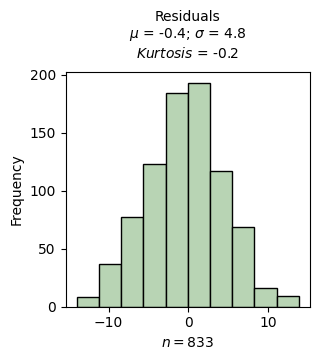

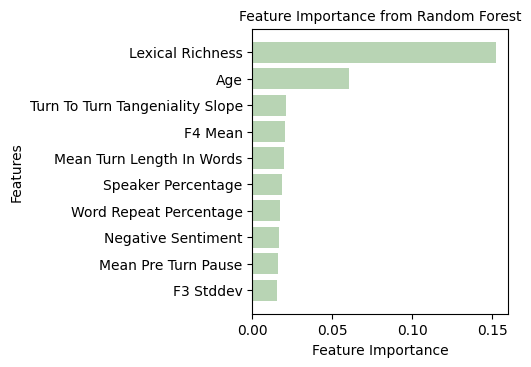

In [25]:
# Model D
# training, testing a model and getting residuals from testing
residuals_positive_d, estimates_positive_d, model_positive_d = train_and_test('panss_ptot', features, df_train_d, df_test_d, dpi=100)
residuals_positive_d, estimates_positive_d, model_positive_d = train_and_test('panss_ptot', features, df_train_d, df_test_d, dpi=200, filename=figure_dir+f"2.2_scatterplot_model-D_panss-positive_rmse.png")

# plotting distributions of the residuals
distribution(residuals_positive_d, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_positive_d, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.2_histogram_model-D_panss-positive_residuals.png")

# feature importance
plot_feature_importance(model_positive_d, features, dpi=100)
plot_feature_importance(model_positive_d, features, dpi=200, filename=figure_dir+f"2.2_feature-imp_model-D_panss-positive.png")

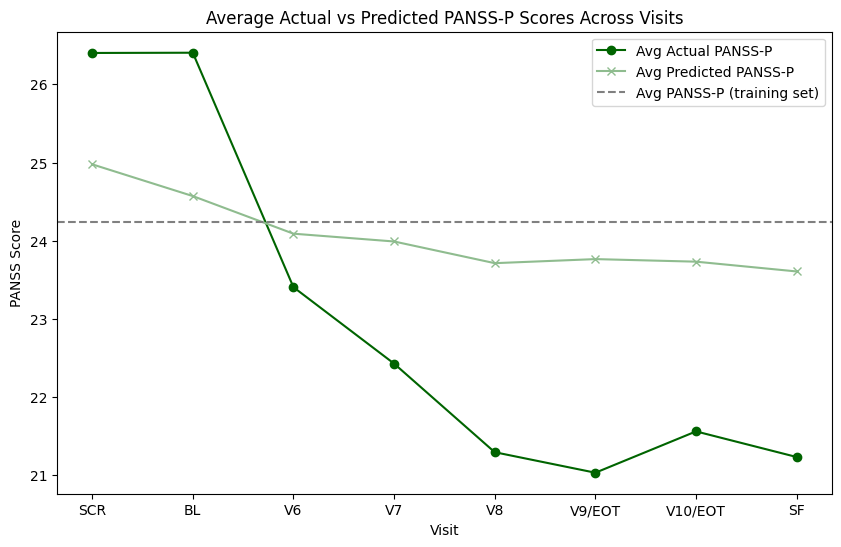

In [26]:
# Average PANSS-P score in training dataset
avg_panss_train = np.mean(df_train_d['panss_ptot'])

# Create a temporary DataFrame to combine Visit and predicted scores
temp_df = pd.DataFrame({'visit_name': df_test_d['visit_name'], 'predicted_panss': estimates_positive_d.iloc[:,0], 'actual_panss': df_test_d['panss_ptot']})

# Calculate average actual and predicted PANSS scores for each visit
avg_scores = temp_df.groupby('visit_name')[['actual_panss', 'predicted_panss']].mean().reset_index()

# ensure visits show up in order
visit_order = ['SCR', 'BL', 'V6', 'V7', 'V8', 'V9/EOT', 'V10/EOT', 'SF'] 
avg_scores['visit_name'] = pd.Categorical(avg_scores['visit_name'], categories = visit_order, ordered = True)
avg_scores = avg_scores.sort_values('visit_name')

# Plotting
plt.figure(figsize=(10, 6))  # Adjust figure size as needed

# Plot average actual and predicted PANSS scores
plt.plot(avg_scores['visit_name'], avg_scores['actual_panss'], label = 'Avg Actual PANSS-P', marker = 'o', color = 'darkgreen')
plt.plot(avg_scores['visit_name'], avg_scores['predicted_panss'], label = 'Avg Predicted PANSS-P', marker = 'x', color = 'darkseagreen')

# Horizontal line for average predicted PANSS from training set
plt.axhline(y = avg_panss_train, color = 'gray', linestyle = '--', label = 'Avg PANSS-P (training set)')

# Calculate and display Pearson correlation at each visit (using original data)
for visit in df_test_d['visit_name'].unique():
    visit_data = df_test_d[df_test_d['visit_name'] == visit]
    visit_predictions = temp_df[temp_df['visit_name'] == visit]['predicted_panss']
    
    #corr, p_value = pearsonr(visit_data['panss'], visit_predictions)
    #avg_predicted_for_visit = avg_scores[avg_scores['visit_name'] == visit]['predicted_panss'].values[0]
    #plt.text(visit, max(visit_data['panss'].mean(), avg_predicted_for_visit) + 0.5, f'r={corr:.2f}', ha='center')

# Add labels, legend, and title
plt.xlabel('Visit')
plt.ylabel('PANSS Score')
#plt.ylim(76,99)
plt.title('Average Actual vs Predicted PANSS-P Scores Across Visits')
plt.legend()
plt.grid(False)
plt.show()

#### 2.3 - Predicting negative symptoms (PANSS-N)

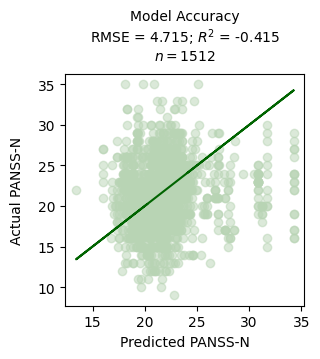

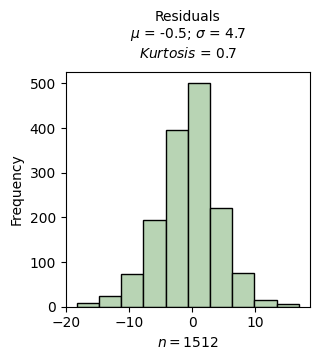

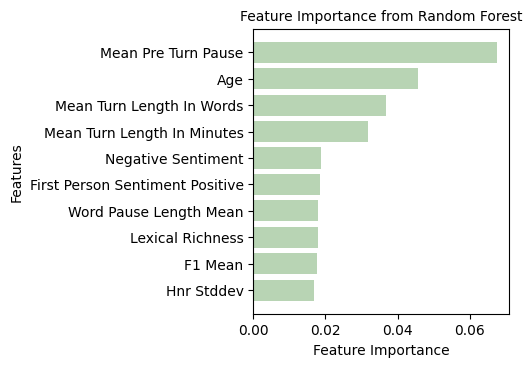

In [27]:
# Model A
# training, testing a model and getting residuals from testing
residuals_negative_a, estimates_negative_a, model_negative_a = train_and_test('panss_ntot', features, df_train_a, df_test_a, dpi=100)
residuals_negative_a, estimates_negative_a, model_negative_a = train_and_test('panss_ntot', features, df_train_a, df_test_a, dpi=200, filename=figure_dir+f"2.3_scatterplot_model-A_panss-negative_rmse.png")

# plotting distributions of the residuals
distribution(residuals_negative_a, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_negative_a, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.3_histogram_model-A_panss-negative_residuals.png")

# feature importance
plot_feature_importance(model_negative_a, features, dpi=100)
plot_feature_importance(model_negative_a, features, dpi=200, filename=figure_dir+f"2.3_feature-imp_model-A_panss-negative.png")

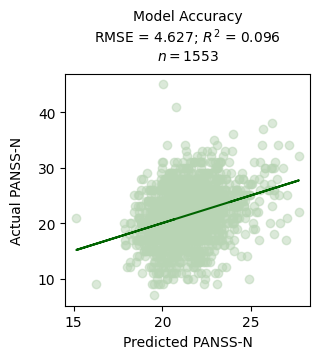

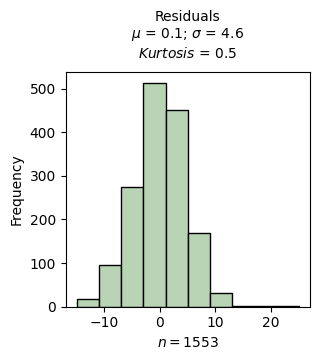

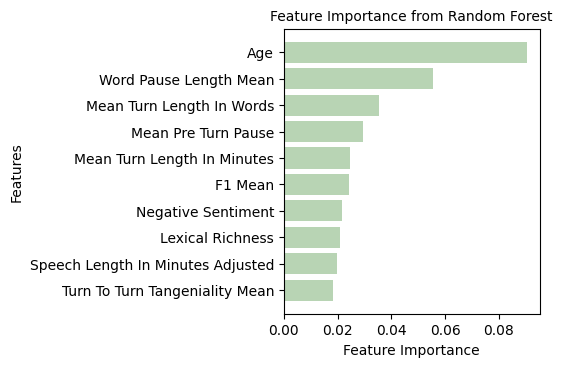

In [28]:
# Model B
# training, testing a model and getting residuals from testing
residuals_negative_b, estimates_negative_b, model_negative_b = train_and_test('panss_ntot', features, df_train_b, df_test_b, dpi=100)
residuals_negative_b, estimates_negative_b, model_negative_b = train_and_test('panss_ntot', features, df_train_b, df_test_b, dpi=200, filename=figure_dir+f"2.3_scatterplot_model-B_panss-negative_rmse.png")

# plotting distributions of the residuals
distribution(residuals_negative_b, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_negative_b, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.3_histogram_model-B_panss-negative_residuals.png")

# feature importance
plot_feature_importance(model_negative_b, features, dpi=100)
plot_feature_importance(model_negative_b, features, dpi=200, filename=figure_dir+f"2.3_feature-imp_model-B_panss-negative.png")

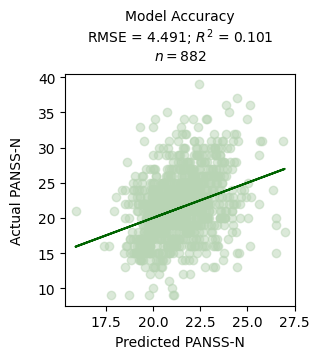

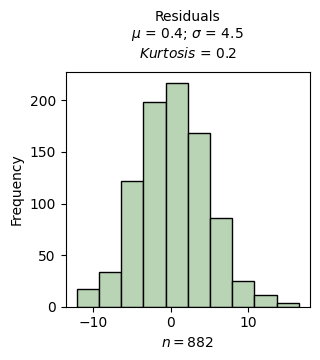

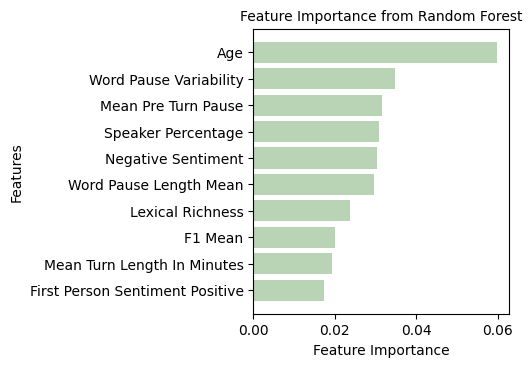

In [29]:
# Model C
# training, testing a model and getting residuals from testing
residuals_negative_c, estimates_negative_c, model_negative_c = train_and_test('panss_ntot', features, df_train_c, df_test_c, dpi=100)
residuals_negative_c, estimates_negative_c, model_negative_c = train_and_test('panss_ntot', features, df_train_c, df_test_c, dpi=200, filename=figure_dir+f"2.3_scatterplot_model-C_panss-negative_rmse.png")

# plotting distributions of the residuals
distribution(residuals_negative_c, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_negative_c, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.3_histogram_model-C_panss-negative_residuals.png")

# feature importance
plot_feature_importance(model_negative_c, features, dpi=100)
plot_feature_importance(model_negative_c, features, dpi=200, filename=figure_dir+f"2.3_feature-imp_model-C_panss-negative.png")

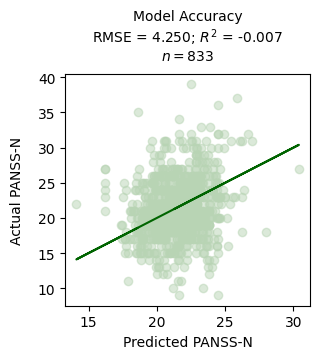

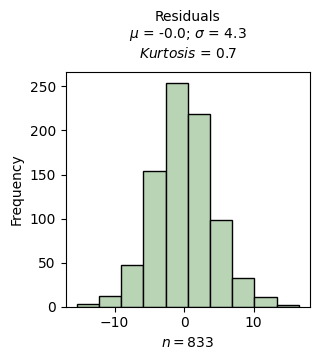

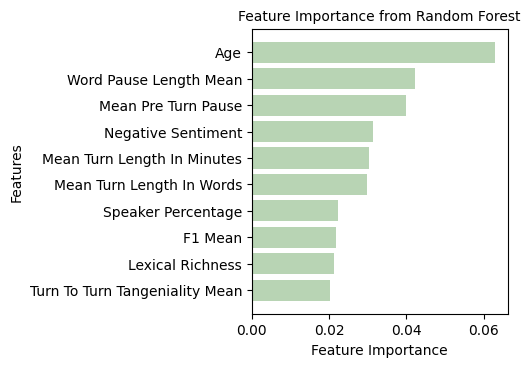

In [30]:
# Model D
# training, testing a model and getting residuals from testing
residuals_negative_d, estimates_negative_d, model_negative_d = train_and_test('panss_ntot', features, df_train_d, df_test_d, dpi=100)
residuals_negative_d, estimates_negative_d, model_negative_d = train_and_test('panss_ntot', features, df_train_d, df_test_d, dpi=200, filename=figure_dir+f"2.3_scatterplot_model-D_panss-negative_rmse.png")

# plotting distributions of the residuals
distribution(residuals_negative_d, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_negative_d, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.3_histogram_model-D_panss-negative_residuals.png")

# feature importance
plot_feature_importance(model_negative_d, features, dpi=100)
plot_feature_importance(model_negative_d, features, dpi=200, filename=figure_dir+f"2.3_feature-imp_model-D_panss-negative.png")

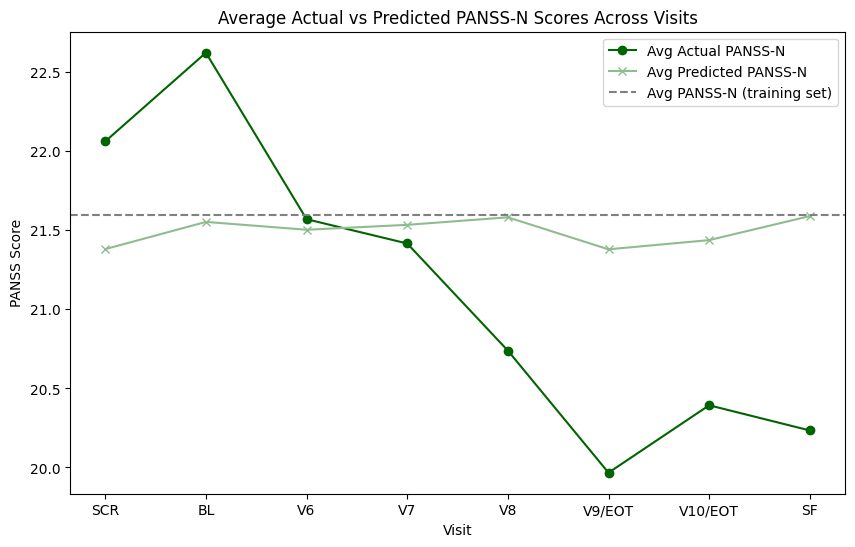

In [31]:
# Average PANSS-N score in training dataset
avg_panss_train = np.mean(df_train_d['panss_ntot'])

# Create a temporary DataFrame to combine Visit and predicted scores
temp_df = pd.DataFrame({'visit_name': df_test_d['visit_name'], 'predicted_panss': estimates_negative_d.iloc[:,0], 'actual_panss': df_test_d['panss_ntot']})

# Calculate average actual and predicted PANSS scores for each visit
avg_scores = temp_df.groupby('visit_name')[['actual_panss', 'predicted_panss']].mean().reset_index()

# ensure visits show up in order
visit_order = ['SCR', 'BL', 'V6', 'V7', 'V8', 'V9/EOT', 'V10/EOT', 'SF'] 
avg_scores['visit_name'] = pd.Categorical(avg_scores['visit_name'], categories = visit_order, ordered = True)
avg_scores = avg_scores.sort_values('visit_name')

# Plotting
plt.figure(figsize=(10, 6))  # Adjust figure size as needed

# Plot average actual and predicted PANSS scores
plt.plot(avg_scores['visit_name'], avg_scores['actual_panss'], label = 'Avg Actual PANSS-N', marker = 'o', color = 'darkgreen')
plt.plot(avg_scores['visit_name'], avg_scores['predicted_panss'], label = 'Avg Predicted PANSS-N', marker = 'x', color = 'darkseagreen')

# Horizontal line for average predicted PANSS from training set
plt.axhline(y = avg_panss_train, color = 'gray', linestyle = '--', label = 'Avg PANSS-N (training set)')

# Calculate and display Pearson correlation at each visit (using original data)
for visit in df_test_d['visit_name'].unique():
    visit_data = df_test_d[df_test_d['visit_name'] == visit]
    visit_predictions = temp_df[temp_df['visit_name'] == visit]['predicted_panss']
    
    #corr, p_value = pearsonr(visit_data['panss'], visit_predictions)
    #avg_predicted_for_visit = avg_scores[avg_scores['visit_name'] == visit]['predicted_panss'].values[0]
    #plt.text(visit, max(visit_data['panss'].mean(), avg_predicted_for_visit) + 0.5, f'r={corr:.2f}', ha='center')

# Add labels, legend, and title
plt.xlabel('Visit')
plt.ylabel('PANSS Score')
#plt.ylim(76,99)
plt.title('Average Actual vs Predicted PANSS-N Scores Across Visits')
plt.legend()
plt.grid(False)
plt.show()

#### 2.4 - Predicting general symptoms (PANSS-G)

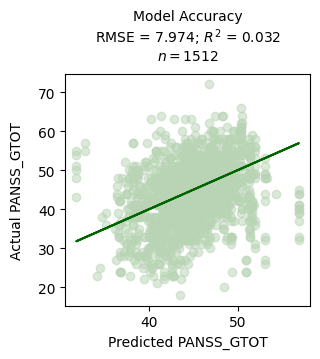

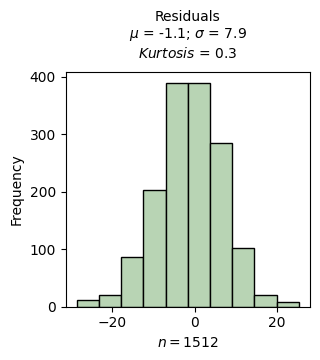

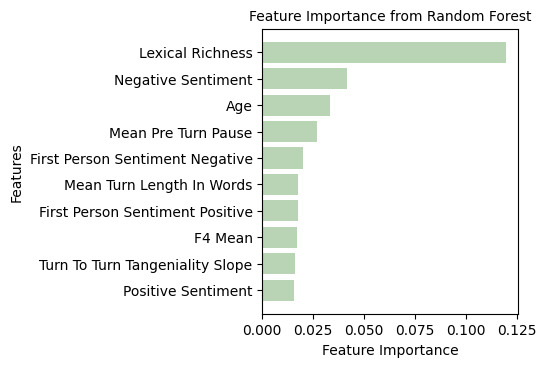

In [32]:
# Model A
# training, testing a model and getting residuals from testing
residuals_general_a, estimates_general_a, model_general_a = train_and_test('panss_gtot', features, df_train_a, df_test_a, dpi=100)
residuals_general_a, estimates_general_a, model_general_a = train_and_test('panss_gtot', features, df_train_a, df_test_a, dpi=200, filename=figure_dir+f"2.4_scatterplot_model-A_panss-general_rmse.png")

# plotting distributions of the residuals
distribution(residuals_general_a, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_general_a, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.4_histogram_model-A_panss-general_residuals.png")

# feature importance
plot_feature_importance(model_general_a, features, dpi=100)
plot_feature_importance(model_general_a, features, dpi=200, filename=figure_dir+f"2.4_feature-imp_model-A_panss-general.png")

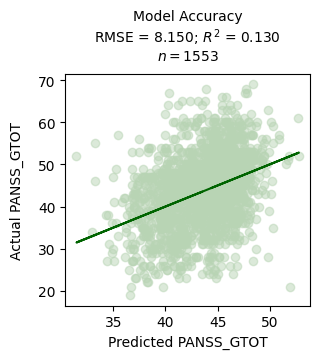

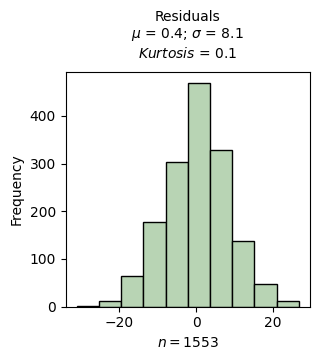

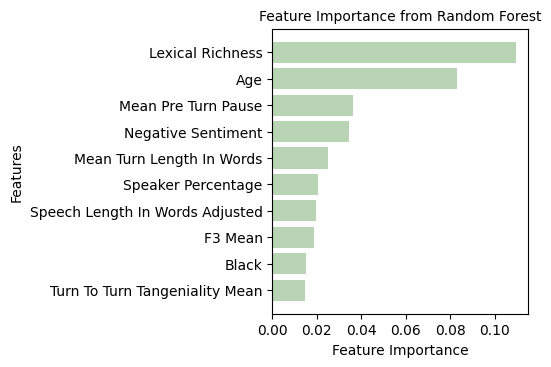

In [33]:
# Model B
# training, testing a model and getting residuals from testing
residuals_general_b, estimates_general_b, model_general_b = train_and_test('panss_gtot', features, df_train_b, df_test_b, dpi=100)
residuals_general_b, estimates_general_b, model_general_b = train_and_test('panss_gtot', features, df_train_b, df_test_b, dpi=200, filename=figure_dir+f"2.4_scatterplot_model-B_panss-general_rmse.png")

# plotting distributions of the residuals
distribution(residuals_general_b, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_general_b, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.4_histogram_model-B_panss-general_residuals.png")

# feature importance
plot_feature_importance(model_general_b, features, dpi=100)
plot_feature_importance(model_general_b, features, dpi=200, filename=figure_dir+f"2.4_feature-imp_model-B_panss-general.png")

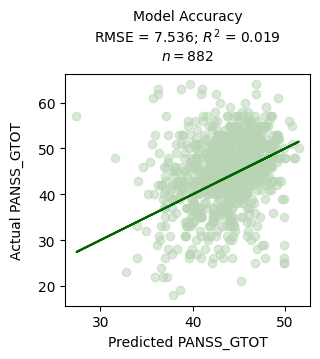

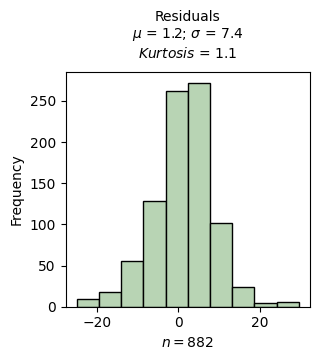

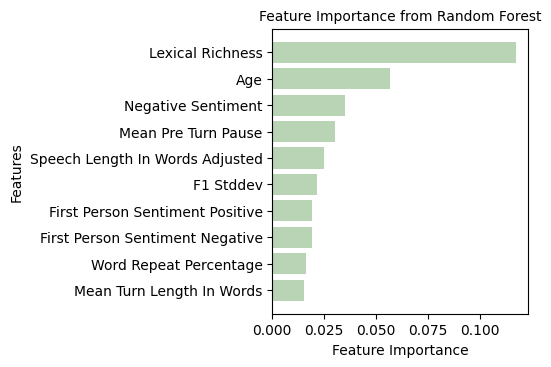

In [34]:
# Model C
# training, testing a model and getting residuals from testing
residuals_general_c, estimates_general_c, model_general_c = train_and_test('panss_gtot', features, df_train_c, df_test_c, dpi=100)
residuals_general_c, estimates_general_c, model_general_c = train_and_test('panss_gtot', features, df_train_c, df_test_c, dpi=200, filename=figure_dir+f"2.4_scatterplot_model-C_panss-general_rmse.png")

# plotting distributions of the residuals
distribution(residuals_general_c, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_general_c, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.4_histogram_model-C_panss-general_residuals.png")

# feature importance
plot_feature_importance(model_general_c, features, dpi=100)
plot_feature_importance(model_general_c, features, dpi=200, filename=figure_dir+f"2.4_feature-imp_model-C_panss-general.png")

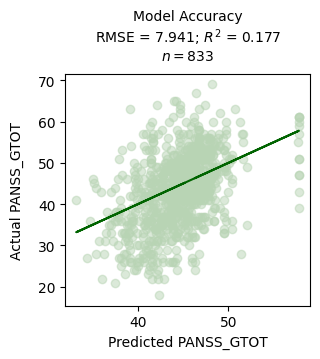

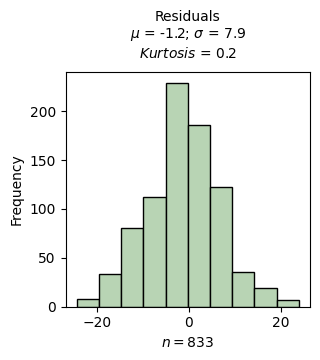

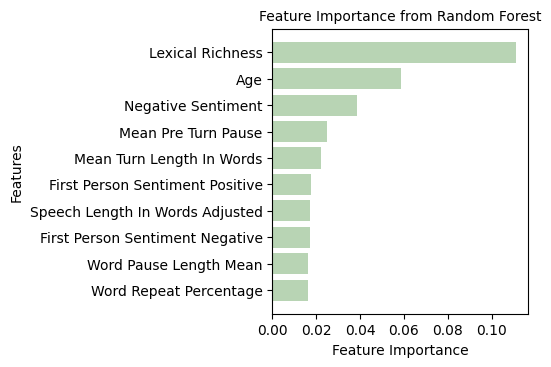

In [35]:
# Model D
# training, testing a model and getting residuals from testing
residuals_general_d, estimates_general_d, model_general_d = train_and_test('panss_gtot', features, df_train_d, df_test_d, dpi=100)
residuals_general_d, estimates_general_d, model_general_d = train_and_test('panss_gtot', features, df_train_d, df_test_d, dpi=200, filename=figure_dir+f"2.4_scatterplot_model-D_panss-general_rmse.png")

# plotting distributions of the residuals
distribution(residuals_general_d, 'residuals', 'Residuals', 'histogram', dpi=100)
distribution(residuals_general_d, 'residuals', 'Residuals', 'histogram', dpi=200, filename=figure_dir+f"2.4_histogram_model-D_panss-general_residuals.png")

# feature importance
plot_feature_importance(model_general_d, features, dpi=100)
plot_feature_importance(model_general_d, features, dpi=200, filename=figure_dir+f"2.4_feature-imp_model-D_panss-general.png")

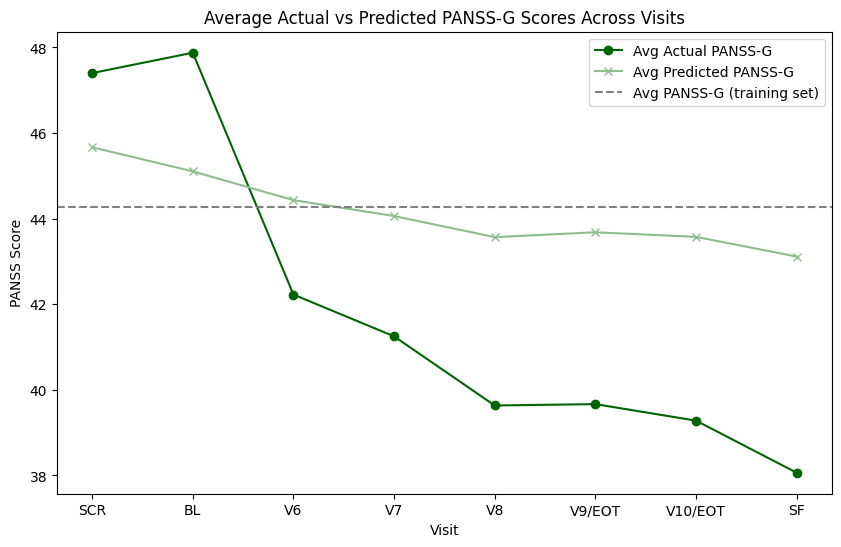

In [36]:
# Average PANSS-G score in training dataset
avg_panss_train = np.mean(df_train_d['panss_gtot'])

# Create a temporary DataFrame to combine Visit and predicted scores
temp_df = pd.DataFrame({'visit_name': df_test_d['visit_name'], 'predicted_panss': estimates_general_d.iloc[:,0], 'actual_panss': df_test_d['panss_gtot']})

# Calculate average actual and predicted PANSS scores for each visit
avg_scores = temp_df.groupby('visit_name')[['actual_panss', 'predicted_panss']].mean().reset_index()

# ensure visits show up in order
visit_order = ['SCR', 'BL', 'V6', 'V7', 'V8', 'V9/EOT', 'V10/EOT', 'SF'] 
avg_scores['visit_name'] = pd.Categorical(avg_scores['visit_name'], categories = visit_order, ordered = True)
avg_scores = avg_scores.sort_values('visit_name')

# Plotting
plt.figure(figsize=(10, 6))  # Adjust figure size as needed

# Plot average actual and predicted PANSS scores
plt.plot(avg_scores['visit_name'], avg_scores['actual_panss'], label = 'Avg Actual PANSS-G', marker = 'o', color = 'darkgreen')
plt.plot(avg_scores['visit_name'], avg_scores['predicted_panss'], label = 'Avg Predicted PANSS-G', marker = 'x', color = 'darkseagreen')

# Horizontal line for average predicted PANSS from training set
plt.axhline(y = avg_panss_train, color = 'gray', linestyle = '--', label = 'Avg PANSS-G (training set)')

# Calculate and display Pearson correlation at each visit (using original data)
for visit in df_test_d['visit_name'].unique():
    visit_data = df_test_d[df_test_d['visit_name'] == visit]
    visit_predictions = temp_df[temp_df['visit_name'] == visit]['predicted_panss']
    
    #corr, p_value = pearsonr(visit_data['panss'], visit_predictions)
    #avg_predicted_for_visit = avg_scores[avg_scores['visit_name'] == visit]['predicted_panss'].values[0]
    #plt.text(visit, max(visit_data['panss'].mean(), avg_predicted_for_visit) + 0.5, f'r={corr:.2f}', ha='center')

# Add labels, legend, and title
plt.xlabel('Visit')
plt.ylabel('PANSS Score')
#plt.ylim(76,99)
plt.title('Average Actual vs Predicted PANSS-G Scores Across Visits')
plt.legend()
plt.grid(False)
plt.show()

### 3 - Wildcard models

Here, develop new models based on the sum of the predictions for each subscale score, compared against models predicting total PANSS scores. 

In [37]:
results_dict_a = {
    'estimates_positive': estimates_positive_a.iloc[:,0],
    'residuals_positive': residuals_positive_a.iloc[:,0],
    'estimates_negative': estimates_negative_a.iloc[:,0],
    'residuals_negative': residuals_negative_a.iloc[:,0],
    'estimates_general': estimates_general_a.iloc[:,0],
    'residuals_general': residuals_general_a.iloc[:,0],
}

results_dict_b = {
    'estimates_positive': estimates_positive_b.iloc[:,0],
    'residuals_positive': residuals_positive_b.iloc[:,0],
    'estimates_negative': estimates_negative_b.iloc[:,0],
    'residuals_negative': residuals_negative_b.iloc[:,0],
    'estimates_general': estimates_general_b.iloc[:,0],
    'residuals_general': residuals_general_b.iloc[:,0],
}

results_dict_c = {
    'estimates_positive': estimates_positive_c.iloc[:,0],
    'residuals_positive': residuals_positive_c.iloc[:,0],
    'estimates_negative': estimates_negative_c.iloc[:,0],
    'residuals_negative': residuals_negative_c.iloc[:,0],
    'estimates_general': estimates_general_c.iloc[:,0],
    'residuals_general': residuals_general_c.iloc[:,0],
}

results_dict_d = {
    'estimates_positive': estimates_positive_d.iloc[:,0],
    'residuals_positive': residuals_positive_d.iloc[:,0],
    'estimates_negative': estimates_negative_d.iloc[:,0],
    'residuals_negative': residuals_negative_d.iloc[:,0],
    'estimates_general': estimates_general_d.iloc[:,0],
    'residuals_general': residuals_general_d.iloc[:,0],
}

In [38]:
results_df_a = pd.DataFrame(results_dict_a)
results_df_b = pd.DataFrame(results_dict_b)
results_df_c = pd.DataFrame(results_dict_c)
results_df_d = pd.DataFrame(results_dict_d)

In [39]:
results_dfs = [results_df_a, results_df_b, results_df_c, results_df_d]

In [40]:
subscales_preds = ['estimates_positive', 'estimates_negative', 'estimates_general']

In [41]:
# sum together the predictions for positive, negative and general subscales for each model

for df in results_dfs:
  df['summed_predictions'] = df[subscales_preds].sum(axis = 1) 

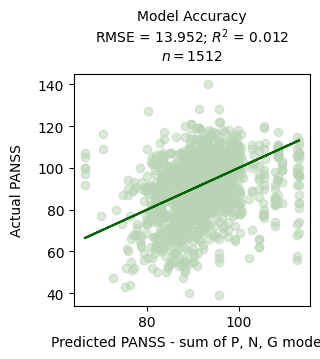

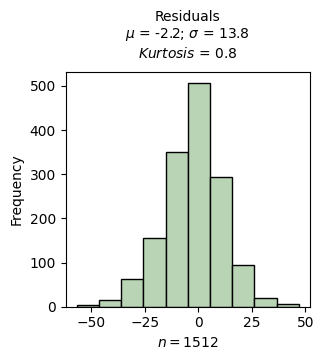

In [42]:
# test and plot summed predictions against actual predictions 

# Model A
y_test = df_test_a['panss']
y_pred = results_df_a['summed_predictions']

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
rsq = r2_score(y_test, y_pred)

# calculate residuals
residuals = pd.DataFrame({"residuals": (y_test - y_pred)}, index = y_test.index)

# plot a figure with the results
scatterplot_rmse(
    y_test,
    y_pred,
    "Actual PANSS",
    "Predicted PANSS - sum of P, N, G models",
    rmse,
    rsq,
    dpi=100,
)
scatterplot_rmse(
    y_test,
    y_pred,
    "Actual PANSS",
    "Predicted PANSS - sum of P, N, G models",
    rmse,
    rsq,
    dpi=100,
    filename=figure_dir+f"6.4.1_scatterplot_model-A_wildcard_rmse.png"
)

# distribution of residuals
distribution(residuals, 'residuals', 'Residuals', 'histogram', dpi = 100)
distribution(residuals, 'residuals', 'Residuals', 'histogram', dpi = 100, filename=figure_dir+f"3.1_histogram_model-A_wildcard_rmse.png")

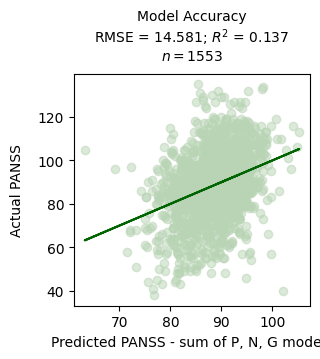

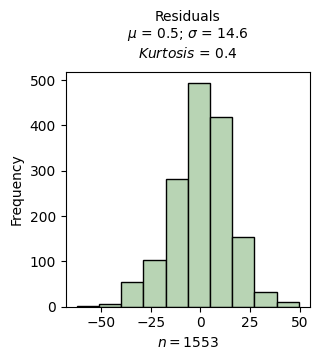

In [43]:
# Model B
y_test = df_test_b['panss']
y_pred = results_df_b['summed_predictions']

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
rsq = r2_score(y_test, y_pred)

# calculate residuals
residuals = pd.DataFrame({"residuals": (y_test - y_pred)}, index = y_test.index)

# plot a figure with the results
scatterplot_rmse(
    y_test,
    y_pred,
    "Actual PANSS",
    "Predicted PANSS - sum of P, N, G models",
    rmse,
    rsq,
    dpi=100,
)
scatterplot_rmse(
    y_test,
    y_pred,
    "Actual PANSS",
    "Predicted PANSS - sum of P, N, G models",
    rmse,
    rsq,
    dpi=100,
    filename=figure_dir+f"6.4.1_scatterplot_model-B_wildcard_rmse.png"
)

# distribution of residuals
distribution(residuals, 'residuals', 'Residuals', 'histogram', dpi = 100)
distribution(residuals, 'residuals', 'Residuals', 'histogram', dpi = 100, filename=figure_dir+f"3.1_histogram_model-B_wildcard_rmse.png")

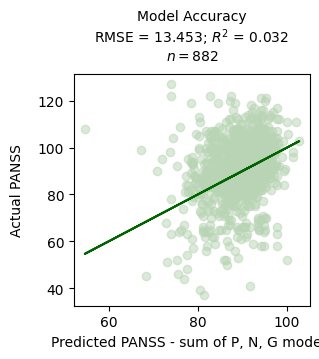

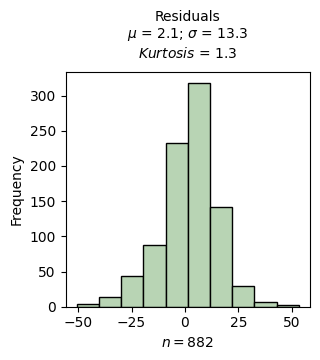

In [44]:
# Model C
y_test = df_test_c['panss']
y_pred = results_df_c['summed_predictions']

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
rsq = r2_score(y_test, y_pred)

# calculate residuals
residuals = pd.DataFrame({"residuals": (y_test - y_pred)}, index = y_test.index)

# plot a figure with the results
scatterplot_rmse(
    y_test,
    y_pred,
    "Actual PANSS",
    "Predicted PANSS - sum of P, N, G models",
    rmse,
    rsq,
    dpi=100,
)
scatterplot_rmse(
    y_test,
    y_pred,
    "Actual PANSS",
    "Predicted PANSS - sum of P, N, G models",
    rmse,
    rsq,
    dpi=100,
    filename=figure_dir+f"6.4.1_scatterplot_model-C_wildcard_rmse.png"
)

# distribution of residuals
distribution(residuals, 'residuals', 'Residuals', 'histogram', dpi = 100)
distribution(residuals, 'residuals', 'Residuals', 'histogram', dpi = 100, filename=figure_dir+f"3.1_histogram_model-C_wildcard_rmse.png")

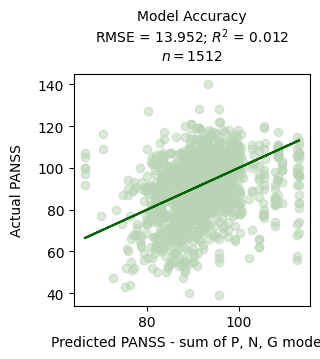

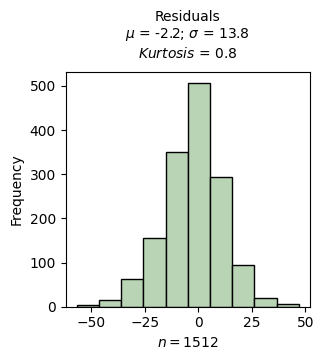

In [45]:
# Model D
y_test = df_test_a['panss']
y_pred = results_df_a['summed_predictions']

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
rsq = r2_score(y_test, y_pred)

# calculate residuals
residuals = pd.DataFrame({"residuals": (y_test - y_pred)}, index = y_test.index)

# plot a figure with the results
scatterplot_rmse(
    y_test,
    y_pred,
    "Actual PANSS",
    "Predicted PANSS - sum of P, N, G models",
    rmse,
    rsq,
    dpi=100,
)
scatterplot_rmse(
    y_test,
    y_pred,
    "Actual PANSS",
    "Predicted PANSS - sum of P, N, G models",
    rmse,
    rsq,
    dpi=100,
    filename=figure_dir+f"6.4.1_scatterplot_model-D_wildcard_rmse.png"
)

# distribution of residuals
distribution(residuals, 'residuals', 'Residuals', 'histogram', dpi = 100)
distribution(residuals, 'residuals', 'Residuals', 'histogram', dpi = 100, filename=figure_dir+f"3.1_histogram_model-D_wildcard_rmse.png")